Практическая работа № 1

Прогнозирование оттока клиентов.

Сравниваем логистическую регрессию, дерево решений и метод ближайших соседей.

ФИО: __________________  Группа: __________

Для запуска нажать «Выполнить всё». Блоки нужно выполнять по порядку.

Данные: https://www.kaggle.com/datasets/blastchar/telco-customer-churn
Для автоматической загрузки используется копия CSV из репозитория IBM.

In [1]:
# Подключаем библиотеки
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

plt.rcParams.update({'figure.dpi': 110, 'font.size': 11})
print('Python:', sys.version.split()[0])
print('pandas:', pd.__version__, '| numpy:', np.__version__)
print('scikit-learn:', sklearn.__version__, '| matplotlib:', matplotlib.__version__)

Python: 3.12.14
pandas: 2.2.3 | numpy: 2.3.5
scikit-learn: 1.8.0 | matplotlib: 3.10.8


1. Просмотр данных

Одна строка — один клиент. Churn показывает, ушёл он или нет: Yes — ушёл, No — остался.

In [2]:
# Читаем CSV из папки, а если его нет — по ссылке
DATA_URL = 'https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv'
local_files = [Path('Telco-Customer-Churn.csv'), Path('WA_Fn-UseC_-Telco-Customer-Churn.csv')]
source = next((p for p in local_files if p.exists()), DATA_URL)
df = pd.read_csv(source)
print(f'Строк: {df.shape[0]}, столбцов: {df.shape[1]}')
display(df.head())
df.info()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Строк: 7043, столбцов: 21
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling

In [3]:
# Проверяем не только NaN, но и строки из пробелов.
blank_counts = df.apply(lambda col: col.astype(str).str.strip().eq('').sum())
display(pd.DataFrame({'Тип при чтении': df.dtypes.astype(str),
                      'NaN': df.isna().sum(), 'Пустые строки': blank_counts}))
print('Полных дубликатов:', df.duplicated().sum())
print('Повторяющихся customerID:', df['customerID'].duplicated().sum())

# TotalCharges — числовой признак, но пробелы приводят к типу object.
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
# SeniorCitizen содержит категории 0/1; кодируем его как категориальный.
df['SeniorCitizen'] = df['SeniorCitizen'].astype(str)
numeric_features = ['tenure', 'MonthlyCharges', 'TotalCharges']
categorical_features = [col for col in df.columns
                        if col not in numeric_features + ['customerID', 'Churn']]
print('Числовые признаки:', ', '.join(numeric_features))
print('Категориальные признаки:', ', '.join(categorical_features))
print('Пропуски после преобразования:')
print(df.isna().sum()[lambda s: s > 0])
display(df[numeric_features].describe())

,Тип при чтении,NaN,Пустые строки
customerID,object,0,0
gender,object,0,0
SeniorCitizen,int64,0,0
Partner,object,0,0
Dependents,object,0,0
tenure,int64,0,0
PhoneService,object,0,0
MultipleLines,object,0,0
InternetService,object,0,0
OnlineSecurity,object,0,0


,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7032.000000
mean,32.371149,64.761692,2283.300441
std,24.559481,30.090047,2266.771362
min,0.000000,18.250000,18.800000
25%,9.000000,35.500000,401.450000
50%,29.000000,70.350000,1397.475000
75%,55.000000,89.850000,3794.737500
max,72.000000,118.750000,8684.800000


Полных дубликатов: 0
Повторяющихся customerID: 0
Числовые признаки: tenure, MonthlyCharges, TotalCharges
Категориальные признаки: gender, SeniorCitizen, Partner, Dependents, PhoneService, MultipleLines, InternetService, OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies, Contract, PaperlessBilling, PaymentMethod
Пропуски после преобразования:
TotalCharges    11
dtype: int64


Всего 7043 строки и 21 столбец. В TotalCharges найдено 11 пустых значений. После перевода в числа они стали NaN. Позже заполним их медианой обучающей выборки.

Числовые признаки: tenure, MonthlyCharges, TotalCharges. SeniorCitizen — категория 0/1, остальные категории перечислены выше. customerID — номер клиента, для обучения его убираем. Churn — ответ, который нужно предсказывать.

,Клиентов,"Доля, %"
Остались (No),5174,73.46
Ушли (Yes),1869,26.54


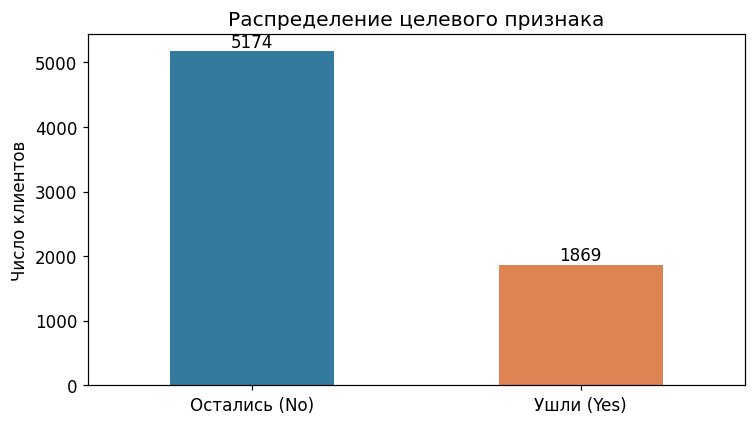

In [4]:
# Считаем, сколько клиентов ушло и сколько осталось
churn_counts = df['Churn'].value_counts().reindex(['No', 'Yes'])
class_table = pd.DataFrame({'Клиентов': churn_counts,
                           'Доля, %': (100 * churn_counts / len(df)).round(2)})
class_table.index = ['Остались (No)', 'Ушли (Yes)']
display(class_table)
ax = class_table['Клиентов'].plot.bar(color=['#347a9e', '#de8452'], rot=0, figsize=(7, 4))
ax.set(title='Распределение целевого признака', ylabel='Число клиентов', xlabel='')
ax.bar_label(ax.containers[0])
plt.tight_layout()
plt.show()

2. Подготовка данных

X — признаки клиентов, y — ответы. 75% данных идут на обучение, 25% — на проверку.

Текстовые категории переводим в числа через OneHotEncoder, числовые признаки масштабируем через StandardScaler. Обработку настраиваем только на обучающей выборке.

In [5]:
# Отделяем признаки от ответов
X = df.drop(columns=['customerID', 'Churn'])
y = df['Churn'].map({'No': 0, 'Yes': 1})
# Делим данные на обучение и проверку
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)
print('Обучающая выборка:', X_train.shape)
print('Тестовая выборка:', X_test.shape)
display(pd.DataFrame({'Обучение': y_train.value_counts(),
                      'Тест': y_test.value_counts()}).rename(index={0: 'Остались', 1: 'Ушли'}))

# Общая обработка признаков для всех трёх моделей
def make_preprocessor():
    # Пропуски заполняем медианой, затем меняем масштаб
    numeric_pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ])
    # Для каждой категории создаём отдельный столбец
    categorical_pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore'))
    ])
    return ColumnTransformer([
        ('numeric', numeric_pipeline, numeric_features),
        ('categorical', categorical_pipeline, categorical_features)
    ])

,Обучение,Тест
Churn,,
Остались,3892,1282
Ушли,1390,479


Обучающая выборка: (5282, 19)
Тестовая выборка: (1761, 19)


3. Обучение моделей

Обучаем три модели и проверяем их на тестовой выборке.
Accuracy — доля правильных ответов. Например, 0.8 означает 80%.

In [6]:
# Создаём три модели
estimators = {
    'Логистическая регрессия': LogisticRegression(max_iter=1000, random_state=42),
    'Дерево решений': DecisionTreeClassifier(random_state=42),
    'k ближайших соседей': KNeighborsClassifier(n_neighbors=5)
}
models, predictions, rows = {}, {}, []
for name, estimator in estimators.items():
    # Объединяем обработку данных и модель
    pipeline = Pipeline([('preprocessing', make_preprocessor()), ('model', estimator)])
    # Обучаем на тренировочных данных
    pipeline.fit(X_train, y_train)
    # Получаем прогнозы для тестовых клиентов
    y_pred = pipeline.predict(X_test)
    models[name] = pipeline
    predictions[name] = y_pred
    # Считаем правильные ответы и ошибки
    rows.append({'Модель': name, 'Accuracy': accuracy_score(y_test, y_pred),
                 'Верных прогнозов': int((y_pred == y_test).sum()),
                 'Ошибок': int((y_pred != y_test).sum())})
results = pd.DataFrame(rows).sort_values('Accuracy', ascending=False).reset_index(drop=True)
results['Accuracy, %'] = (100 * results['Accuracy']).round(2)
display(results)
# Для сравнения: всем предсказываем самый частый класс
majority_class = y_train.mode().iloc[0]
baseline_accuracy = accuracy_score(y_test, np.full(len(y_test), majority_class))
print(f'Базовый прогноз (всем присвоить частый класс обучения): {baseline_accuracy:.2%}')

,Модель,Accuracy,Верных прогнозов,Ошибок,"Accuracy, %"
0,Логистическая регрессия,0.812606,1431,330,81.26
1,k ближайших соседей,0.767746,1352,409,76.77
2,Дерево решений,0.736513,1297,464,73.65


Базовый прогноз (всем присвоить частый класс обучения): 72.80%


4. Сравнение результатов

Чем выше столбец, тем больше правильных прогнозов.

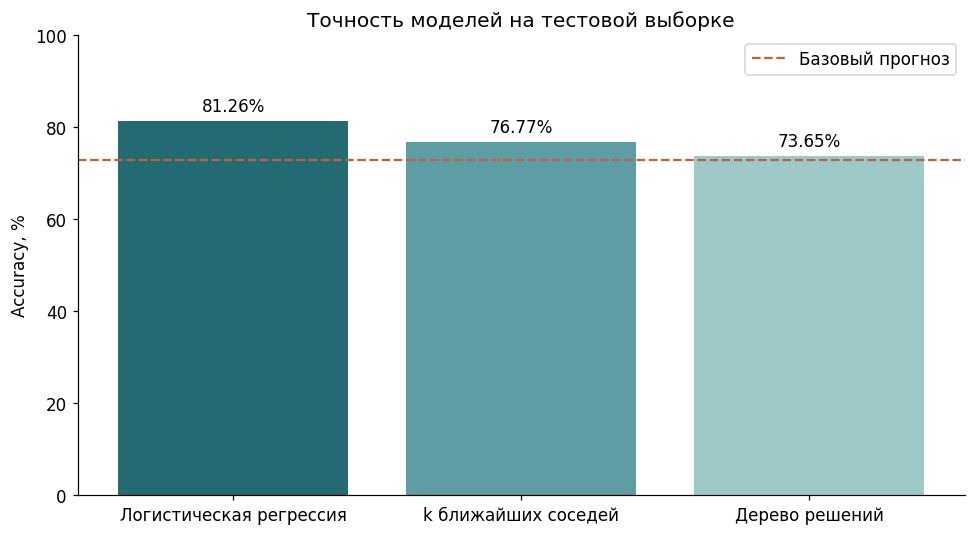

Лучший результат на этом разбиении: Логистическая регрессия, Accuracy = 0.8126


In [7]:
# Строим график точности
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(results['Модель'], results['Accuracy'] * 100,
              color=['#246a73', '#5e9da4', '#9dc9c9'])
ax.axhline(baseline_accuracy * 100, color='#bd6439', linestyle='--', label='Базовый прогноз')
ax.bar_label(bars, labels=[f'{v:.2f}%' for v in results['Accuracy'] * 100], padding=4)
ax.set(ylim=(0, 100), ylabel='Accuracy, %', title='Точность моделей на тестовой выборке')
ax.legend(loc='upper right')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()
# Выбираем модель с наибольшей Accuracy
best_name = results.loc[0, 'Модель']
print(f'Лучший результат на этом разбиении: {best_name}, Accuracy = {results.loc[0, "Accuracy"]:.4f}')

5. Матрица ошибок

Строки — настоящие ответы, столбцы — прогнозы. 0 — остался, 1 — ушёл.
TN и TP — правильные ответы. FP — остался, но предсказан уход. FN — ушёл, но модель решила, что остался.

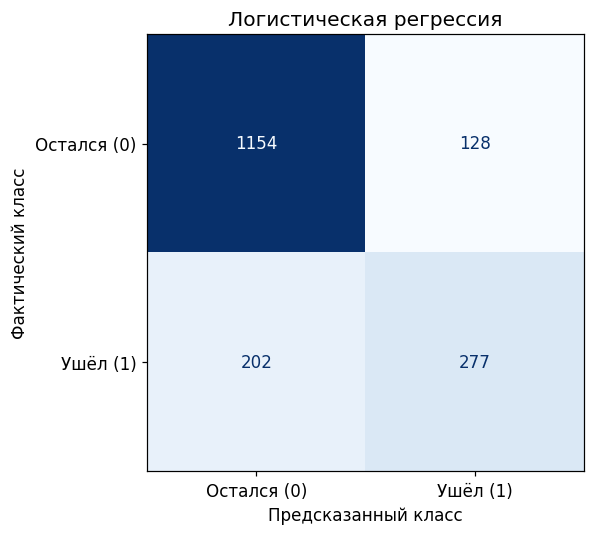

TN = 1154, FP = 128, FN = 202, TP = 277
Ошибочно предсказаны как ушедшие: 128 клиентов (FP).
Ошибочно предсказаны как лояльные: 202 клиентов (FN).
Всего ошибок: 330 из 1761.
Проверка Accuracy по матрице: 0.8126


In [8]:
# Сравниваем прогноз лучшей модели с настоящими ответами
cm = confusion_matrix(y_test, predictions[best_name], labels=[0, 1])
# Четыре числа из матрицы: два вида верных ответов и два вида ошибок
tn, fp, fn, tp = cm.ravel()
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(cm, display_labels=['Остался (0)', 'Ушёл (1)']).plot(
    ax=ax, cmap='Blues', colorbar=False, values_format='d'
)
ax.set(title=best_name, xlabel='Предсказанный класс', ylabel='Фактический класс')
plt.tight_layout()
plt.show()
print(f'TN = {tn}, FP = {fp}, FN = {fn}, TP = {tp}')
print(f'Ошибочно предсказаны как ушедшие: {fp} клиентов (FP).')
print(f'Ошибочно предсказаны как лояльные: {fn} клиентов (FN).')
print(f'Всего ошибок: {fp + fn} из {len(y_test)}.')
print(f'Проверка Accuracy по матрице: {(tn + tp) / cm.sum():.4f}')
assert cm.sum() == len(y_test)
assert np.isclose((tn + tp) / cm.sum(), results.loc[0, 'Accuracy'])

6. Вывод

In [9]:
# Вывод с результатами текущего запуска
print(f'Обучены и проверены три модели на {len(df)} клиентах.')
print(f'Лучший результат: {best_name}.')
print(f'Точность: {results.loc[0, "Accuracy"]:.2%}.')
print(f'Правильных прогнозов: {tn + tp} из {len(y_test)}.')
print(f'Ошибочно предсказан уход: {fp} клиентов.')
print(f'Ошибочно предсказано, что клиент остался: {fn} клиентов.')
print('Оставшихся клиентов больше, чем ушедших, поэтому смотрим и на точность, и на ошибки.')
print('Результаты относятся к этому разбиению данных.')

Обучены и проверены три модели на 7043 клиентах.
Лучший результат: Логистическая регрессия.
Точность: 81.26%.
Правильных прогнозов: 1431 из 1761.
Ошибочно предсказан уход: 128 клиентов.
Ошибочно предсказано, что клиент остался: 202 клиентов.
Оставшихся клиентов больше, чем ушедших, поэтому смотрим и на точность, и на ошибки.
Результаты относятся к этому разбиению данных.
